Số lượng quan sát hợp lệ cho mô hình Hiệu năng: 4453 dòng.


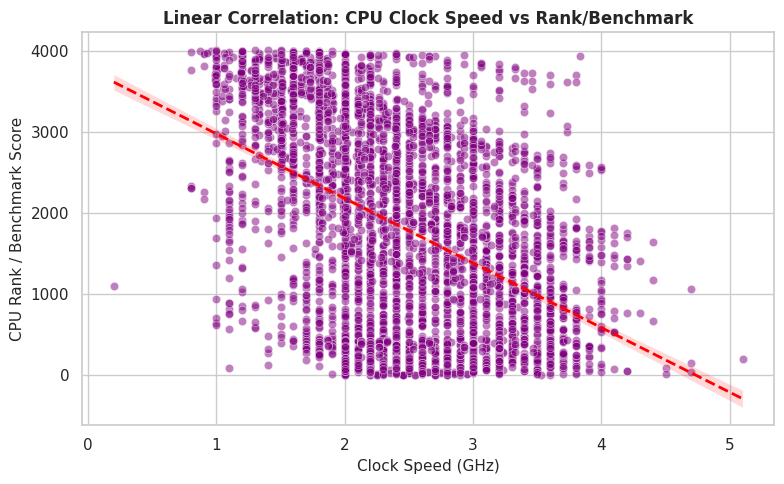


--- KẾT QUẢ HUẤN LUYỆN MỚI (Hiệu năng CPU) ---
Hệ số chặn (theta_0): 1824.9349
Hệ số góc (theta_1):  -566.2404
Chi phí MSE cuối cùng: 586471.0319


In [8]:
# ==============================================================================
# ĐIỀU CHỈNH BIẾN ĐẦU VÀO X (speed_ghz) VÀ BIẾN MỤC TIÊU Y (rank)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Nạp và làm sạch dữ liệu với biến mới
dataset_path = 'Final_CPU_Data_Cleaned.csv'
df = pd.read_csv(dataset_path)

# Lọc bỏ các dòng thiếu speed_ghz hoặc rank
df_clean = df.dropna(subset=['speed_ghz', 'rank']).copy()
df_clean = df_clean[(df_clean['speed_ghz'] > 0) & (df_clean['rank'] > 0)]

# Gán biến X và y theo đúng thống nhất của nhóm
X_raw = df_clean[['speed_ghz']].values
y_raw = df_clean[['rank']].values

print(f"Số lượng quan sát hợp lệ cho mô hình Hiệu năng: {len(df_clean)} dòng.")

# 2. Trực quan hóa tương quan mới: Tốc độ xung nhịp vs Thứ hạng/Hiệu năng
plt.figure(figsize=(8, 5))
sns.regplot(x=df_clean['speed_ghz'], y=df_clean['rank'], 
            scatter_kws={'alpha':0.5, 'color':'purple', 'edgecolor': 'w', 'linewidths': 0.5}, 
            line_kws={'color':'red', 'linewidth': 2, 'linestyle': '--'})
plt.title('Linear Correlation: CPU Clock Speed vs Rank/Benchmark', fontsize=12, fontweight='bold')
plt.xlabel('Clock Speed (GHz)', fontsize=11)
plt.ylabel('CPU Rank / Benchmark Score', fontsize=11)
plt.tight_layout()
plt.show()

# ==============================================================================
# 3. HUẤN LUYỆN MÔ HÌNH VỚI DỮ LIỆU MỚI (Gradient Descent & Normal Equation)
# ==============================================================================
# Chuẩn hóa dữ liệu X
X_mean = np.mean(X_raw)
X_std = np.std(X_raw)
X_scaled = (X_raw - X_mean) / X_std

m = len(X_raw)
X_b = np.c_[np.ones((m, 1)), X_scaled]
y_vec = y_raw.reshape(-1, 1)

def compute_cost(X, y, theta):
    predictions = X.dot(theta)
    errors = predictions - y
    return (1 / (2 * len(y))) * np.sum(np.square(errors))

def gradient_descent(X, y, theta, learning_rate, iterations):
    cost_history = np.zeros(iterations)
    for i in range(iterations):
        predictions = X.dot(theta)
        errors = predictions - y
        gradients = (1 / len(y)) * X.T.dot(errors)
        theta = theta - learning_rate * gradients
        cost_history[i] = compute_cost(X, y, theta)
    return theta, cost_history

# Chạy Gradient Descent
theta_initial = np.random.randn(2, 1)
alpha = 0.1
iterations = 500
theta_gd, cost_history = gradient_descent(X_b, y_vec, theta_initial, alpha, iterations)

print("\n--- KẾT QUẢ HUẤN LUYỆN MỚI (Hiệu năng CPU) ---")
print(f"Hệ số chặn (theta_0): {theta_gd[0][0]:.4f}")
print(f"Hệ số góc (theta_1):  {theta_gd[1][0]:.4f}")
print(f"Chi phí MSE cuối cùng: {cost_history[-1]:.4f}")

In [9]:
# ==============================================================================
# NHIỆM VỤ 3, 4, 5: XÂY DỰNG COST FUNCTION, GRADIENT DESCENT VÀ NORMAL EQUATION
# ==============================================================================
import pandas as pd
import numpy as np

# 1. Nạp và chuẩn bị dữ liệu (speed_ghz vs rank)
df = pd.read_csv('Final_CPU_Data_Cleaned.csv')
df_clean = df.dropna(subset=['speed_ghz', 'rank']).copy()
df_clean = df_clean[(df_clean['speed_ghz'] > 0) & (df_clean['rank'] > 0)]

X_raw = df_clean[['speed_ghz']].values
y_vec = df_clean[['rank']].values.reshape(-1, 1)

# Chuẩn hóa Z-score cho X (Bắt buộc để Gradient Descent hội tụ tốt)
X_mean = np.mean(X_raw)
X_std = np.std(X_raw)
X_scaled = (X_raw - X_mean) / X_std

# Thêm cột 1 (bias) vào ma trận X_b
m = len(X_raw)
X_b = np.c_[np.ones((m, 1)), X_scaled]

# ------------------------------------------------------------------------------
# NHIỆM VỤ 3: Xây dựng hàm Cost Function (MSE)
# ------------------------------------------------------------------------------
def compute_cost(X, y, theta):
    predictions = X.dot(theta)
    errors = predictions - y
    return (1 / (2 * m)) * np.sum(np.square(errors))

# ------------------------------------------------------------------------------
# NHIỆM VỤ 4: Xây dựng thuật toán Gradient Descent
# ------------------------------------------------------------------------------
def gradient_descent(X, y, theta, learning_rate, iterations):
    cost_history = np.zeros(iterations)
    for i in range(iterations):
        predictions = X.dot(theta)
        errors = predictions - y
        gradients = (1 / m) * X.T.dot(errors)
        theta = theta - learning_rate * gradients
        cost_history[i] = compute_cost(X, y, theta)
    return theta, cost_history

# Khởi tạo siêu tham số (Dùng chung cho cả nhóm để dễ so sánh)
alpha = 0.1
iterations = 500
theta_initial = np.zeros((2, 1)) # Gán bằng 0 thay vì random để kết quả cố định tuyệt đối

theta_gd, cost_history = gradient_descent(X_b, y_vec, theta_initial, alpha, iterations)

# ------------------------------------------------------------------------------
# NHIỆM VỤ 5: Nghiệm Giải tích (Normal Equation)
# ------------------------------------------------------------------------------
def normal_equation(X, y):
    # Công thức: theta = (X^T * X)^-1 * X^T * y
    return np.linalg.inv(X.T.dot(X)).dot(X.T).dot(y)

theta_analytic = normal_equation(X_b, y_vec)

# ==============================================================================
# IN KẾT QUẢ ĐỂ CROSS-CHECK VỚI XUÂN HẠ
# ==============================================================================
print("--- KẾT QUẢ TỪ GRADIENT DESCENT (Nhiệm vụ 4) ---")
print(f"Hệ số chặn (theta_0): {theta_gd[0][0]:.4f}")
print(f"Hệ số góc (theta_1):  {theta_gd[1][0]:.4f}")
print(f"Chi phí MSE cuối cùng: {cost_history[-1]:.4f}\n")

print("--- KẾT QUẢ TỪ NGHIỆM GIẢI TÍCH (Nhiệm vụ 5) ---")
print(f"Hệ số chặn (theta_0): {theta_analytic[0][0]:.4f}")
print(f"Hệ số góc (theta_1):  {theta_analytic[1][0]:.4f}\n")

# So sánh độ chênh lệch
sai_so = np.sum(np.abs(theta_gd - theta_analytic))
print(f"=> Độ chênh lệch giữa 2 phương pháp: {sai_so:.8f} (Càng sát 0 càng chuẩn)")

--- KẾT QUẢ TỪ GRADIENT DESCENT (Nhiệm vụ 4) ---
Hệ số chặn (theta_0): 1824.9349
Hệ số góc (theta_1):  -566.2404
Chi phí MSE cuối cùng: 586471.0319

--- KẾT QUẢ TỪ NGHIỆM GIẢI TÍCH (Nhiệm vụ 5) ---
Hệ số chặn (theta_0): 1824.9349
Hệ số góc (theta_1):  -566.2404

=> Độ chênh lệch giữa 2 phương pháp: 0.00000000 (Càng sát 0 càng chuẩn)


In [ ]:
# ==============================================================================
# NHIỆM VỤ 6, 7, 8 (PHẦN CỦA ĐẠT SANG): ĐÁNH GIÁ VÀ TRỰC QUAN HÓA
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Đảm bảo sử dụng kết quả theta_gd và X_b, y_vec từ Task của Hạ
y_pred = X_b.dot(theta_gd)

# ------------------------------------------------------------------------------
# NHIỆM VỤ 8: Tính toán các chỉ số đánh giá mô hình (MSE, RMSE, R^2)
# ------------------------------------------------------------------------------
# 1. Tính MSE (Mean Squared Error) và RMSE
# Lưu ý: Hàm cost_function ở trên tính 1/(2m), nên MSE thực tế = Cost * 2
mse = np.mean(np.square(y_pred - y_vec))
rmse = np.sqrt(mse)

# 2. Tính R-squared (R^2)
ss_total = np.sum(np.square(y_vec - np.mean(y_vec)))
ss_res = np.sum(np.square(y_vec - y_pred))
r2_score = 1 - (ss_res / ss_total)

print("--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH (Đối chiếu với Đạt Sang) ---")
print(f"MSE (Sai số toàn phương trung bình): {mse:.4f}")
print(f"RMSE (Độ lệch chuẩn của sai số):     {rmse:.4f} (bậc hạng)")
print(f"R^2 (Hệ số xác định):                {r2_score:.4f}")

# ------------------------------------------------------------------------------
# NHIỆM VỤ 6 & 7: Trực quan hóa 3D Cost Surface và Contour Plot
# ------------------------------------------------------------------------------
# Tạo không gian lưới (grid) xung quanh điểm tối ưu (theta_gd)
theta0_range = np.linspace(theta_gd[0][0] - 2000, theta_gd[0][0] + 2000, 50)
theta1_range = np.linspace(theta_gd[1][0] - 2000, theta_gd[1][0] + 2000, 50)
T0, T1 = np.meshgrid(theta0_range, theta1_range)
J_vals = np.zeros((len(theta0_range), len(theta1_range)))

# Tính Cost cho từng tọa độ
for i in range(len(theta0_range)):
    for j in range(len(theta1_range)):
        t = np.array([[theta0_range[i]], [theta1_range[j]]])
        # Dùng lại hàm compute_cost ở task trước
        J_vals[i, j] = compute_cost(X_b, y_vec, t)

J_vals = J_vals.T # Chuyển vị để khớp trục tọa độ

# Thiết lập figure
fig = plt.figure(figsize=(16, 7))
plt.style.use('default') # Chuyển về nền trắng mặc định để 3D rõ nét

# 1. Biểu đồ 3D Cost Surface
ax1 = fig.add_subplot(121, projection='3d')
surf = ax1.plot_surface(T0, T1, J_vals, cmap='plasma', alpha=0.8, edgecolor='none')
ax1.scatter(theta_gd[0][0], theta_gd[1][0], cost_history[-1], color='red', s=100, label='Global Minimum')
ax1.set_title('3D Cost Surface', fontsize=14, fontweight='bold', pad=20)
ax1.set_xlabel('Theta 0 (Intercept)', labelpad=10)
ax1.set_ylabel('Theta 1 (Slope)', labelpad=10)
ax1.set_zlabel('Cost J', labelpad=10)
ax1.legend()

# 2. Biểu đồ Contour (Đường đồng mức)
ax2 = fig.add_subplot(122)
# Dùng logspace để vẽ các vòng đồng mức hội tụ đẹp mắt về tâm
levels = np.logspace(np.log10(np.min(J_vals)), np.log10(np.max(J_vals)), 30)
contour = ax2.contour(T0, T1, J_vals, levels=levels, cmap='plasma')
ax2.scatter(theta_gd[0][0], theta_gd[1][0], color='red', marker='x', s=150, linewidths=3, label='Global Minimum')
ax2.set_title('Contour Plot of Cost Function', fontsize=14, fontweight='bold', pad=20)
ax2.set_xlabel('Theta 0 (Intercept)')
ax2.set_ylabel('Theta 1 (Slope)')
ax2.legend()

plt.tight_layout()
plt.show()